# 3 · Neuroevolution of a PINN

NSGA-II over twelve genes (architecture, learning rate, collocation count, five loss weights),
minimising validation error and parameter count. See
[Lesson 3](../docs/lessons/03-neuroevolution.md) and
[docs/neuroevolution_search.md](../docs/neuroevolution_search.md).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from pinncfd import io, plotting as P

torch.set_num_threads(1)  # one thread: reductions in a fixed order, reproducible outputs
P.use_style()
DEG = np.pi / 180
ROOT = Path("..").resolve()
RESULTS = ROOT / "validation" / "results"
CK = RESULTS / "checkpoints"
DEVICE = "cpu"
from pinncfd.neuroevolution_search import genome as G
from pinncfd.neuroevolution_search.nsga import crowding_distance, fast_non_dominated_sort

Non-dominated sorting and crowding distance on a small hand-made set:

In [2]:
pts = [(0.03, 6000), (0.02, 9000), (0.03, 8000), (0.05, 4500), (0.06, 9000), (0.025, 7000)]
fronts = fast_non_dominated_sort(pts)
for k, f in enumerate(fronts):
    d = crowding_distance([pts[i] for i in f])
    print(f"front {k}: " + ", ".join(f"{pts[i]} d={di:.2f}" for i, di in zip(f, d)))

front 0: (0.03, 6000) d=1.39, (0.02, 9000) d=inf, (0.05, 4500) d=inf, (0.025, 7000) d=1.00
front 1: (0.03, 8000) d=inf
front 2: (0.06, 9000) d=inf


The 40 genomes of the search, and its final front:

0.0241    6851  6×32 silu, lr 1.4e-03, N 192, w body/tan/kutta/far/data 5.41/6.61/15.4/3.16/63.9
0.0375    5795  5×32 tanh, lr 3.2e-04, N 384, w body/tan/kutta/far/data 42.6/0.15/1.02/0.282/9.07
0.1480    4483  3×32 tanh, FF 16@0.96, lr 3.2e-04, N 192, w body/tan/kutta/far/data 29.4/0.15/1.02/1.24/9.07


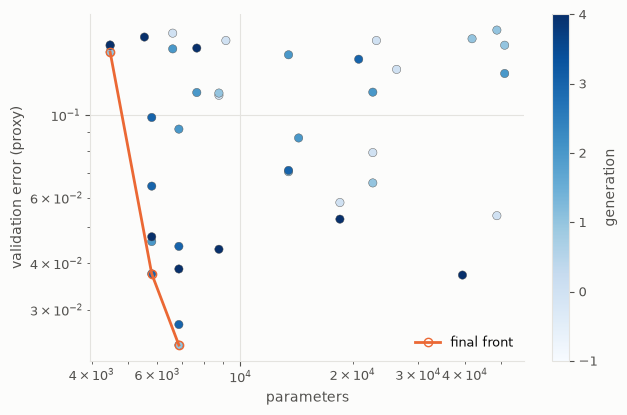

In [3]:
state = json.loads((RESULTS / "phase3_search.json").read_text())
ev = state["evaluated"]
err = np.array([e["fitness"]["error"] for e in ev])
npar = np.array([e["fitness"]["n_params"] for e in ev])
front = fast_non_dominated_sort([(e["fitness"]["error"], e["fitness"]["n_params"]) for e in state["population"]])[0]
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(npar, err, c=[e["generation"] for e in ev], cmap="Blues", vmin=-1, vmax=4, edgecolors=P.TEXT_MUTED, lw=0.3)
fp = sorted((state["population"][i]["fitness"]["n_params"], state["population"][i]["fitness"]["error"]) for i in front)
ax.plot(*zip(*fp), "o-", mfc="none", color=P.SERIES[1], label="final front")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("parameters"); ax.set_ylabel("validation error (proxy)")
fig.colorbar(sc, label="generation"); ax.legend();
for i in sorted(front, key=lambda i: state["population"][i]["fitness"]["error"]):
    ind = state["population"][i]
    print(f"{ind['fitness']['error']:.4f}  {ind['fitness']['n_params']:6d}  {G.describe(ind['genome'])}")

What the genes did (with the caveats of Lesson 3: one seed, genes shared by descent):

In [4]:
for gene in ("activation", "fourier_features", "depth"):
    vals = sorted({e["genome"][gene] for e in ev}, key=str)
    print(gene + ": " + ", ".join(
        f"{v}: median {np.median([e['fitness']['error'] for e in ev if e['genome'][gene] == v]):.3f} "
        f"(n={sum(e['genome'][gene] == v for e in ev)})" for v in vals))

activation: silu: median 0.079 (n=10), sin: median 0.115 (n=11), tanh: median 0.071 (n=19)
fourier_features: 0: median 0.065 (n=26), 16: median 0.154 (n=12), 32: median 0.146 (n=2)
depth: 3: median 0.154 (n=7), 4: median 0.113 (n=5), 5: median 0.058 (n=11), 6: median 0.079 (n=17)


The champion against the hand-tuned network at the full budget (seed 0):

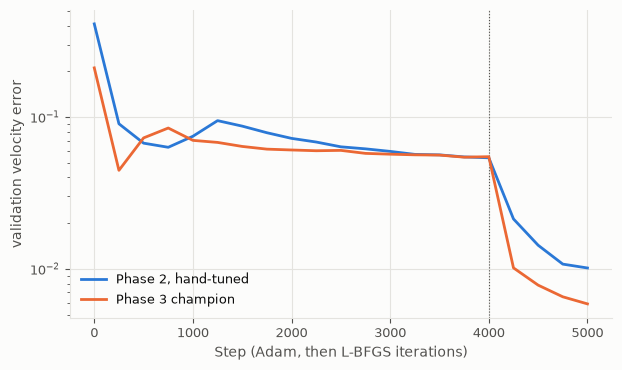

In [5]:
h2 = json.loads((RESULTS / "phase2_histories.json").read_text())["physics_data/0"]
h3 = json.loads((RESULTS / "phase3_histories.json").read_text())["champion/0"]
fig, ax = plt.subplots(figsize=(7, 4))
P.convergence_plot(ax, h2, label="Phase 2, hand-tuned", color=P.SERIES[0], adam_steps=4000)
P.convergence_plot(ax, h3, label="Phase 3 champion", color=P.SERIES[1])
ax.set_ylabel("validation velocity error"); ax.legend();